<a href="https://colab.research.google.com/github/Kavin-Prakash-T/bus-passenger-demand-prediction/blob/main/ProjectWorkDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
uploaded = files.upload()

Saving bus_passenger_demand.csv to bus_passenger_demand.csv


In [ ]:
df = pd.read_csv("bus_passenger_demand.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,date,route_number,hour,day_of_week,weather,holiday,bus_type,peak_hour,weekend,passengers
0,2025-01-24,M1,15.0,4,Clear,0.0,Express,0,0,23.0
1,2025-05-08,P21,10.0,3,NaN,0.0,Ordinary,0,0,45.0
2,2025-01-15,101,10.0,2,Clear,0.0,Express,0,0,56.0
3,2025-01-24,5E,5.0,4,Clear,0.0,Ordinary,0,0,26.0
4,2025-06-21,70,7.0,5,Cloudy,0.0,Express,1,1,63.0


In [ ]:
df.tail()

,date,route_number,hour,day_of_week,weather,holiday,bus_type,peak_hour,weekend,passengers
615,2025-05-09,M1,7.0,4,Cloudy,0.0,Ordinary,1,0,69.0
616,2025-01-04,5E,20.0,5,Clear,0.0,Deluxe,0,1,11.0
617,2025-04-13,23C,8.0,6,Clear,0.0,Ordinary,1,1,58.0
618,2025-02-08,27B,18.0,5,Clear,0.0,Express,1,1,76.0
619,2025-02-24,M1,19.0,0,Clear,1.0,Ordinary,1,0,69.0


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 620
Number of columns: 10


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 620 entries, 0 to 619
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          620 non-null    object 
 1   route_number  620 non-null    object 
 2   hour          615 non-null    float64
 3   day_of_week   620 non-null    int64  
 4   weather       612 non-null    object 
 5   holiday       616 non-null    float64
 6   bus_type      614 non-null    object 
 7   peak_hour     620 non-null    int64  
 8   weekend       620 non-null    int64  
 9   passengers    613 non-null    float64
dtypes: float64(3), int64(3), object(4)
memory usage: 48.6+ KB


In [ ]:
print("Columns in the dataset:\n")

for column in df.columns:
    print(column)

Columns in the dataset:

date
route_number
hour
day_of_week
weather
holiday
bus_type
peak_hour
weekend
passengers


In [ ]:
df.describe()

,hour,day_of_week,holiday,peak_hour,weekend,passengers
count,615.000000,620.000000,616.000000,620.000000,620.000000,613.000000
mean,13.131707,3.067742,0.073052,0.356452,0.314516,59.779772
std,5.261923,2.037276,0.260433,0.479338,0.464698,24.694912
min,5.000000,0.000000,0.000000,0.000000,0.000000,5.000000
25%,9.000000,1.000000,0.000000,0.000000,0.000000,42.000000
50%,13.000000,3.000000,0.000000,0.000000,0.000000,58.000000
75%,18.000000,5.000000,0.000000,1.000000,1.000000,77.000000
max,22.000000,6.000000,1.000000,1.000000,1.000000,138.000000


In [ ]:
df.describe(include="all")

,date,route_number,hour,day_of_week,weather,holiday,bus_type,peak_hour,weekend,passengers
count,620,620,615.000000,620.000000,612,616.000000,614,620.000000,620.000000,613.000000
unique,172,10,NaN,NaN,3,NaN,3,NaN,NaN,NaN
top,2025-04-09,5E,NaN,NaN,Clear,NaN,Ordinary,NaN,NaN,NaN
freq,12,77,NaN,NaN,367,NaN,393,NaN,NaN,NaN
mean,NaN,NaN,13.131707,3.067742,NaN,0.073052,NaN,0.356452,0.314516,59.779772
std,NaN,NaN,5.261923,2.037276,NaN,0.260433,NaN,0.479338,0.464698,24.694912
min,NaN,NaN,5.000000,0.000000,NaN,0.000000,NaN,0.000000,0.000000,5.000000
25%,NaN,NaN,9.000000,1.000000,NaN,0.000000,NaN,0.000000,0.000000,42.000000
50%,NaN,NaN,13.000000,3.000000,NaN,0.000000,NaN,0.000000,0.000000,58.000000
75%,NaN,NaN,18.000000,5.000000,NaN,0.000000,NaN,1.000000,1.000000,77.000000


In [ ]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
date            0
route_number    0
hour            5
day_of_week     0
weather         8
holiday         4
bus_type        6
peak_hour       0
weekend         0
passengers      7
dtype: int64


In [ ]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": missing_percentage
})

missing_table

,Missing Values,Percentage
date,0,0.000000
route_number,0,0.000000
hour,5,0.806452
day_of_week,0,0.000000
weather,8,1.290323
holiday,4,0.645161
bus_type,6,0.967742
peak_hour,0,0.000000
weekend,0,0.000000
passengers,7,1.129032


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 20


In [ ]:
duplicates = df[df.duplicated(keep=False)]

duplicates.head(20)

,date,route_number,hour,day_of_week,weather,holiday,bus_type,peak_hour,weekend,passengers
11,2025-06-16,5E,21.0,0,Cloudy,0.0,Ordinary,0,0,31.0
30,2025-04-06,23C,22.0,6,Cloudy,0.0,Express,0,1,37.0
63,2025-04-14,570,11.0,0,Clear,0.0,Ordinary,0,0,109.0
65,2025-01-21,21G,10.0,1,Clear,0.0,Ordinary,0,0,86.0
89,2025-06-16,5E,21.0,0,Cloudy,0.0,Ordinary,0,0,31.0
91,2025-01-18,27B,12.0,5,Cloudy,0.0,Ordinary,0,1,46.0
94,2025-04-20,27B,16.0,6,Clear,0.0,Ordinary,0,1,52.0
97,2025-02-18,101,16.0,1,Rain,0.0,Ordinary,0,0,49.0
100,2025-03-27,23C,21.0,3,Rain,0.0,Ordinary,0,0,26.0
115,2025-01-18,27B,12.0,5,Cloudy,0.0,Ordinary,0,1,46.0


In [ ]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:")
print(df.shape)

Dataset shape after removing duplicates:
(600, 10)


In [ ]:
# Remove rows where target variable is missing
df = df.dropna(subset=["passengers"])

print("Shape after removing rows with missing passenger count:")
print(df.shape)

Shape after removing rows with missing passenger count:
(593, 10)


In [ ]:
# Numerical columns
df["hour"] = df["hour"].fillna(
    df["hour"].median()
)

df["holiday"] = df["holiday"].fillna(
    df["holiday"].mode()[0]
)

# Categorical columns
df["weather"] = df["weather"].fillna(
    df["weather"].mode()[0]
)

df["bus_type"] = df["bus_type"].fillna(
    df["bus_type"].mode()[0]
)

In [ ]:
print(df.isnull().sum())

date            0
route_number    0
hour            0
day_of_week     0
weather         0
holiday         0
bus_type        0
peak_hour       0
weekend         0
passengers      0
dtype: int64


In [ ]:
df["date"] = pd.to_datetime(df["date"])

df.head()

,date,route_number,hour,day_of_week,weather,holiday,bus_type,peak_hour,weekend,passengers
0,2025-01-24,M1,15.0,4,Clear,0.0,Express,0,0,23.0
1,2025-05-08,P21,10.0,3,Clear,0.0,Ordinary,0,0,45.0
2,2025-01-15,101,10.0,2,Clear,0.0,Express,0,0,56.0
3,2025-01-24,5E,5.0,4,Clear,0.0,Ordinary,0,0,26.0
4,2025-06-21,70,7.0,5,Cloudy,0.0,Express,1,1,63.0


In [ ]:
df["year"] = df["date"].dt.year

df["month"] = df["date"].dt.month

df["day"] = df["date"].dt.day

df["week_of_year"] = (
    df["date"].dt.isocalendar().week.astype(int)
)

df["day_name"] = df["date"].dt.day_name()

df.head()

,date,route_number,hour,day_of_week,weather,holiday,bus_type,peak_hour,weekend,passengers,year,month,day,week_of_year,day_name
0,2025-01-24,M1,15.0,4,Clear,0.0,Express,0,0,23.0,2025,1,24,4,Friday
1,2025-05-08,P21,10.0,3,Clear,0.0,Ordinary,0,0,45.0,2025,5,8,19,Thursday
2,2025-01-15,101,10.0,2,Clear,0.0,Express,0,0,56.0,2025,1,15,3,Wednesday
3,2025-01-24,5E,5.0,4,Clear,0.0,Ordinary,0,0,26.0,2025,1,24,4,Friday
4,2025-06-21,70,7.0,5,Cloudy,0.0,Express,1,1,63.0,2025,6,21,25,Saturday


In [ ]:
print("Number of routes:", df["route_number"].nunique())

print("\nRoutes:")
print(df["route_number"].unique())

Number of routes: 10

Routes:
['M1' 'P21' '101' '5E' '70' '570' '21G' '27B' '23C' '18D']


In [ ]:
route_counts = df["route_number"].value_counts()

route_counts

,count
route_number,
5E,75
101,68
23C,66
570,62
M1,60
70,57
21G,56
27B,55
18D,54


In [ ]:
df["weather"].value_counts()

,count
weather,
Clear,359
Cloudy,144
Rain,90


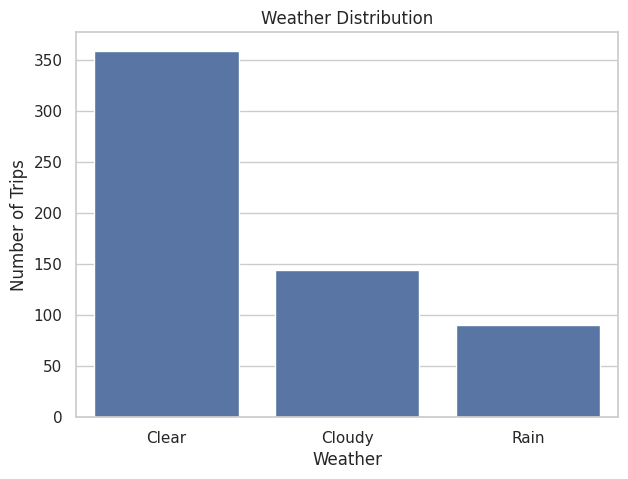

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="weather"
)

plt.title("Weather Distribution")
plt.xlabel("Weather")
plt.ylabel("Number of Trips")

plt.show()

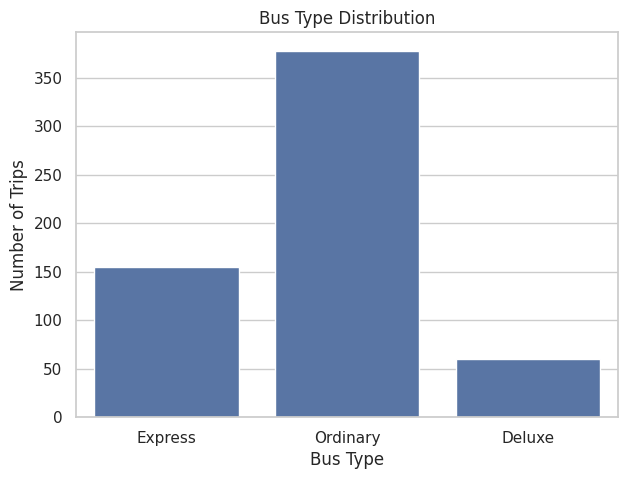

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="bus_type"
)

plt.title("Bus Type Distribution")
plt.xlabel("Bus Type")
plt.ylabel("Number of Trips")

plt.show()

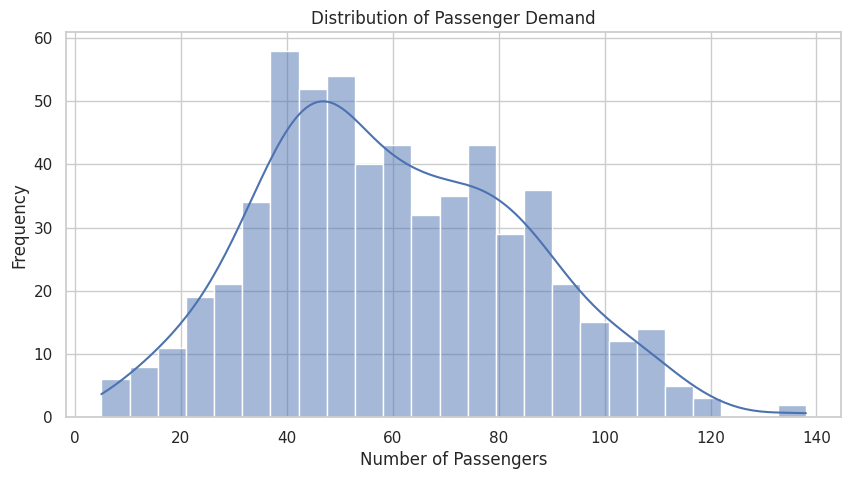

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["passengers"],
    bins=25,
    kde=True
)

plt.title("Distribution of Passenger Demand")
plt.xlabel("Number of Passengers")
plt.ylabel("Frequency")

plt.show()

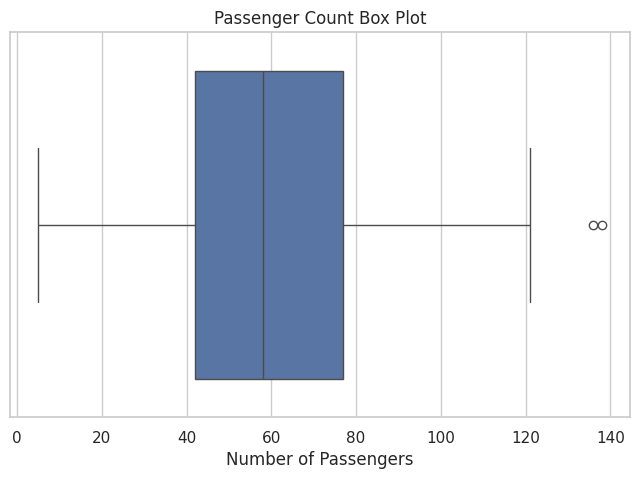

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=df["passengers"]
)

plt.title("Passenger Count Box Plot")
plt.xlabel("Number of Passengers")

plt.show()

In [ ]:
route_demand = (
    df.groupby("route_number")["passengers"]
    .mean()
    .sort_values(ascending=False)
)

route_demand

,passengers
route_number,
570,91.596774
21G,74.410714
P21,67.975000
27B,66.000000
18D,58.314815
101,55.544118
5E,51.560000
23C,48.424242
70,47.315789


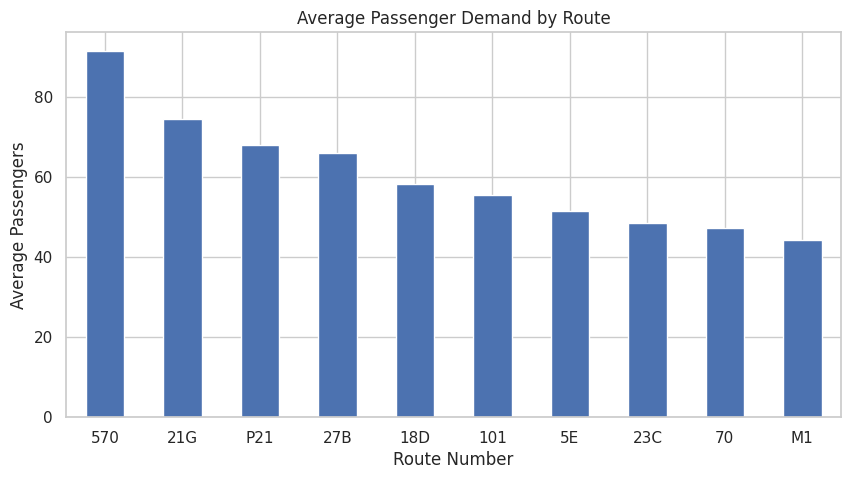

In [ ]:
plt.figure(figsize=(10, 5))

route_demand.plot(kind="bar")

plt.title("Average Passenger Demand by Route")
plt.xlabel("Route Number")
plt.ylabel("Average Passengers")

plt.xticks(rotation=0)

plt.show()

In [ ]:
hour_demand = (
    df.groupby("hour")["passengers"]
    .mean()
)

hour_demand

,passengers
hour,
5.0,41.700000
6.0,42.657895
7.0,79.766667
8.0,79.771429
9.0,84.000000
10.0,51.333333
11.0,56.347826
12.0,50.950000
13.0,52.437500


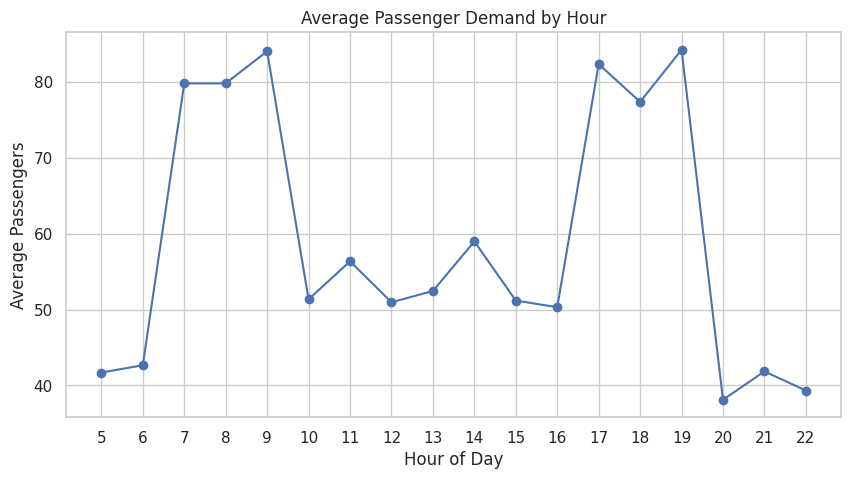

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    hour_demand.index,
    hour_demand.values,
    marker="o"
)

plt.title("Average Passenger Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Passengers")

plt.xticks(range(5, 23))

plt.grid(True)

plt.show()

In [ ]:
peak_demand = (
    df.groupby("peak_hour")["passengers"]
    .mean()
)

peak_demand

,passengers
peak_hour,
0,47.863158
1,81.436620


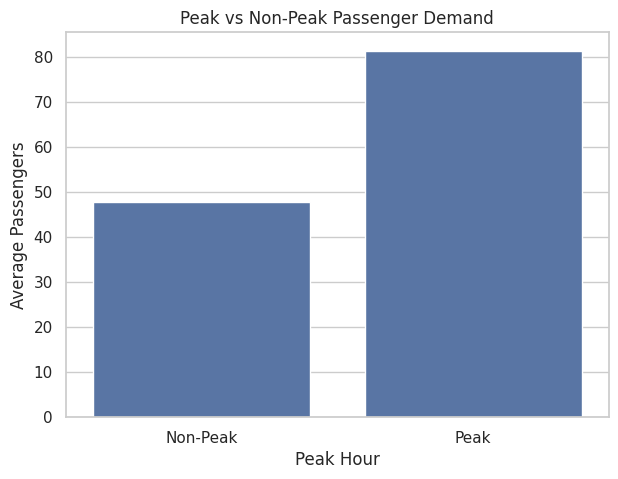

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=peak_demand.index,
    y=peak_demand.values
)

plt.title("Peak vs Non-Peak Passenger Demand")
plt.xlabel("Peak Hour")
plt.ylabel("Average Passengers")

plt.xticks(
    [0, 1],
    ["Non-Peak", "Peak"]
)

plt.show()

In [ ]:
weekend_demand = (
    df.groupby("weekend")["passengers"]
    .mean()
)

weekend_demand

,passengers
weekend,
0,62.750611
1,53.635870


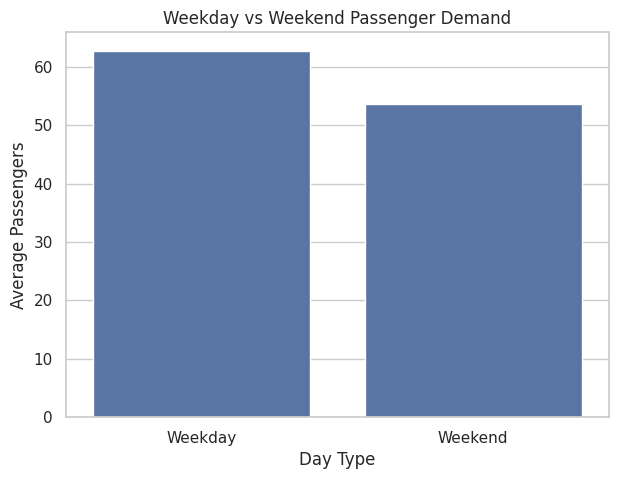

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=weekend_demand.index,
    y=weekend_demand.values
)

plt.title("Weekday vs Weekend Passenger Demand")
plt.xlabel("Day Type")
plt.ylabel("Average Passengers")

plt.xticks(
    [0, 1],
    ["Weekday", "Weekend"]
)

plt.show()

In [ ]:
weather_demand = (
    df.groupby("weather")["passengers"]
    .mean()
    .sort_values(ascending=False)
)

weather_demand

,passengers
weather,
Clear,62.994429
Cloudy,58.486111
Rain,49.966667


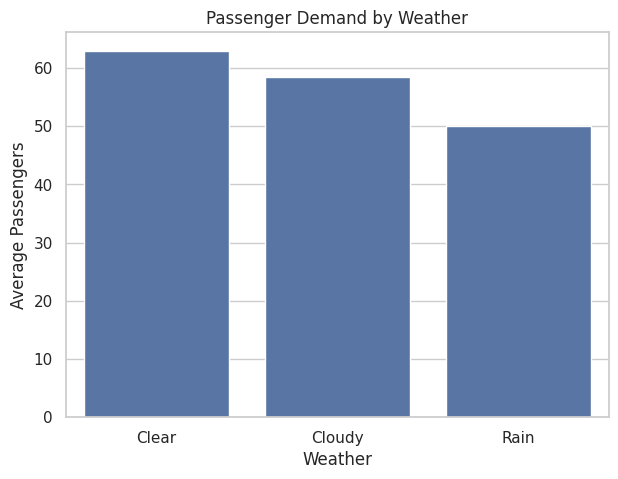

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=weather_demand.index,
    y=weather_demand.values
)

plt.title("Passenger Demand by Weather")
plt.xlabel("Weather")
plt.ylabel("Average Passengers")

plt.show()

In [ ]:
bus_demand = (
    df.groupby("bus_type")["passengers"]
    .mean()
    .sort_values(ascending=False)
)

bus_demand

,passengers
bus_type,
Ordinary,62.708995
Express,57.200000
Deluxe,49.400000


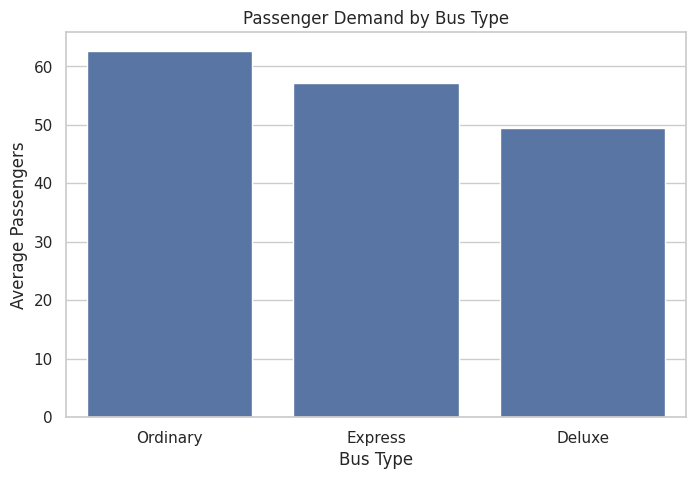

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=bus_demand.index,
    y=bus_demand.values
)

plt.title("Passenger Demand by Bus Type")
plt.xlabel("Bus Type")
plt.ylabel("Average Passengers")

plt.show()

In [ ]:
day_demand = (
    df.groupby("day_name")["passengers"]
    .mean()
)

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_demand = day_demand.reindex(day_order)

day_demand

,passengers
day_name,
Monday,63.647727
Tuesday,61.692308
Wednesday,61.259259
Thursday,65.097826
Friday,61.442857
Saturday,53.978261
Sunday,53.293478


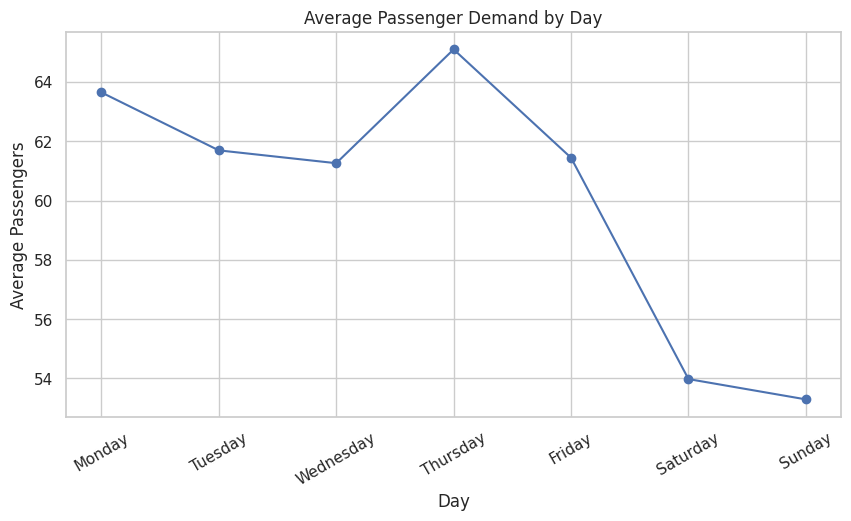

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    day_demand.index,
    day_demand.values,
    marker="o"
)

plt.title("Average Passenger Demand by Day")
plt.xlabel("Day")
plt.ylabel("Average Passengers")

plt.xticks(rotation=30)

plt.grid(True)

plt.show()

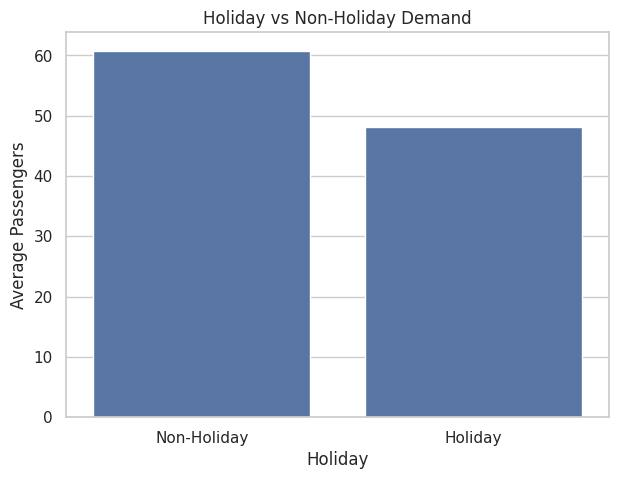

In [ ]:
holiday_demand = (
    df.groupby("holiday")["passengers"]
    .mean()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=holiday_demand.index,
    y=holiday_demand.values
)

plt.title("Holiday vs Non-Holiday Demand")
plt.xlabel("Holiday")
plt.ylabel("Average Passengers")

plt.xticks(
    [0, 1],
    ["Non-Holiday", "Holiday"]
)

plt.show()

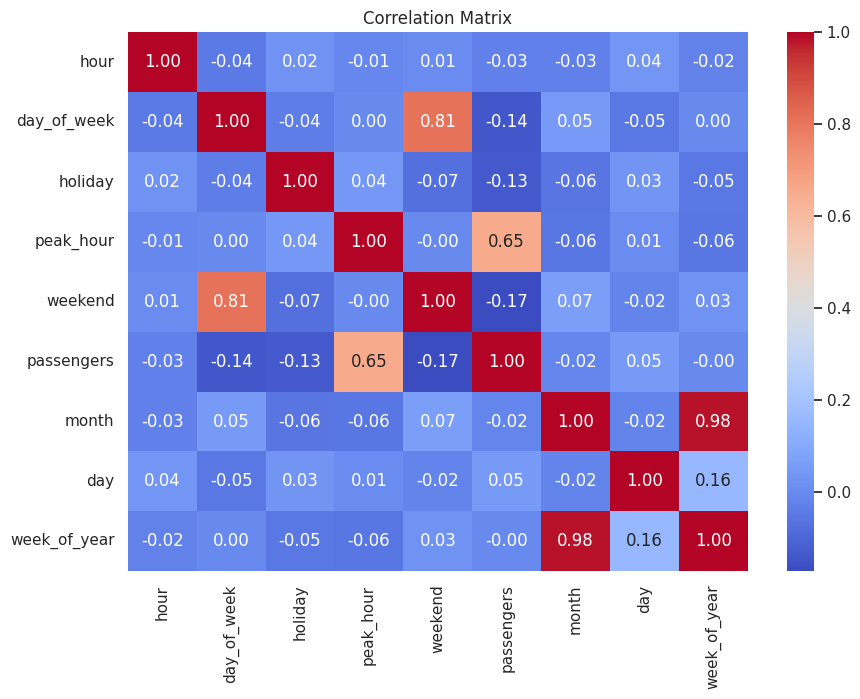

In [ ]:
numeric_columns = [
    "hour",
    "day_of_week",
    "holiday",
    "peak_hour",
    "weekend",
    "passengers",
    "month",
    "day",
    "week_of_year"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [ ]:
def classify_demand(passengers):

    if passengers <= 40:
        return "Low"

    elif passengers <= 80:
        return "Medium"

    else:
        return "High"


df["demand_level"] = (
    df["passengers"]
    .apply(classify_demand)
)

df.head()

,date,route_number,hour,day_of_week,weather,holiday,bus_type,peak_hour,weekend,passengers,year,month,day,week_of_year,day_name,demand_level
0,2025-01-24,M1,15.0,4,Clear,0.0,Express,0,0,23.0,2025,1,24,4,Friday,Low
1,2025-05-08,P21,10.0,3,Clear,0.0,Ordinary,0,0,45.0,2025,5,8,19,Thursday,Medium
2,2025-01-15,101,10.0,2,Clear,0.0,Express,0,0,56.0,2025,1,15,3,Wednesday,Medium
3,2025-01-24,5E,5.0,4,Clear,0.0,Ordinary,0,0,26.0,2025,1,24,4,Friday,Low
4,2025-06-21,70,7.0,5,Cloudy,0.0,Express,1,1,63.0,2025,6,21,25,Saturday,Medium


In [ ]:
print(
    df["demand_level"].value_counts()
)

demand_level
Medium    323
Low       138
High      132
Name: count, dtype: int64


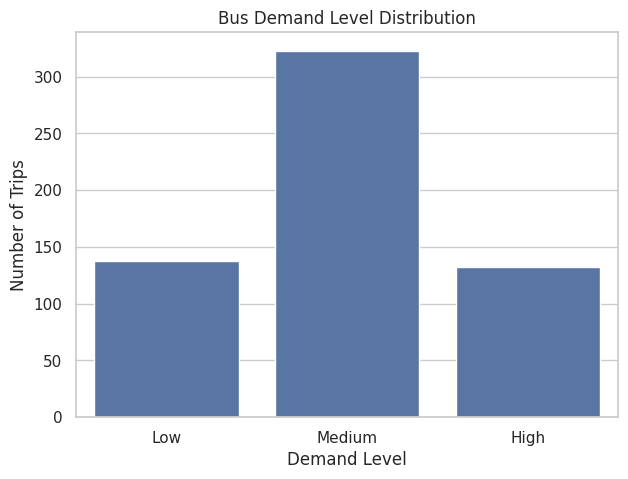

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="demand_level"
)

plt.title("Bus Demand Level Distribution")
plt.xlabel("Demand Level")
plt.ylabel("Number of Trips")

plt.show()

In [ ]:
features = [
    "route_number",
    "hour",
    "day_of_week",
    "weather",
    "holiday",
    "bus_type",
    "peak_hour",
    "weekend",
    "month",
    "day",
    "week_of_year"
]

X = df[features]

y = df["passengers"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (593, 11)
y shape: (593,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 474
Testing records: 119


In [ ]:
categorical_features = [
    "route_number",
    "weather",
    "bus_type"
]

numerical_features = [
    "hour",
    "day_of_week",
    "holiday",
    "peak_hour",
    "weekend",
    "month",
    "day",
    "week_of_year"
]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

In [ ]:
linear_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LinearRegression()
        )
    ]
)

linear_model.fit(
    X_train,
    y_train
)

linear_prediction = linear_model.predict(
    X_test
)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [ ]:
random_forest = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=15,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest.fit(
    X_train,
    y_train
)

rf_prediction = random_forest.predict(
    X_test
)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
gradient_boosting = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=150,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

gradient_boosting.fit(
    X_train,
    y_train
)

gb_prediction = gradient_boosting.predict(
    X_test
)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [ ]:
def evaluate_model(
    model_name,
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    return {
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 4)
    }

In [ ]:
results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_prediction
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_prediction
    )
)

results.append(
    evaluate_model(
        "Gradient Boosting",
        y_test,
        gb_prediction
    )
)

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,7.42,9.26,0.8663
1,Random Forest,8.02,10.18,0.8384
2,Gradient Boosting,7.22,9.34,0.8640


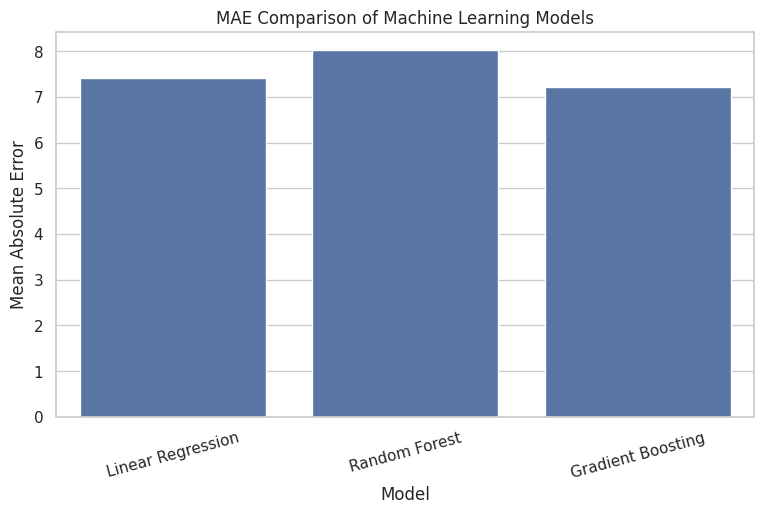

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title("MAE Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")

plt.xticks(rotation=15)

plt.show()

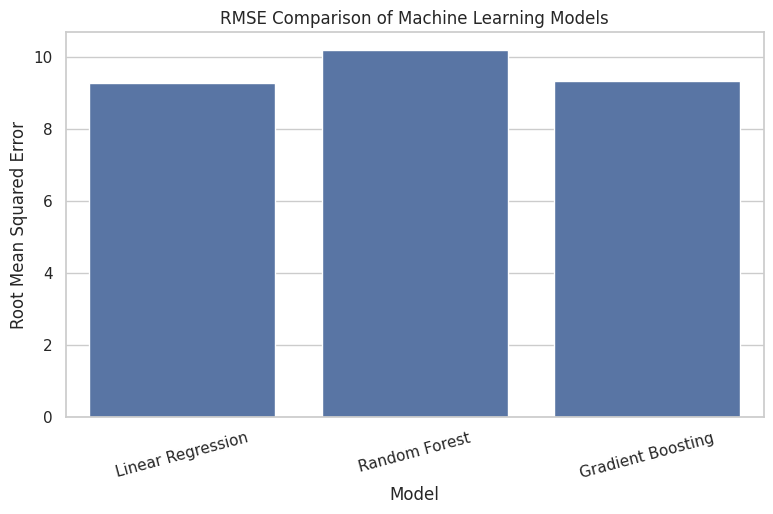

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Root Mean Squared Error")

plt.xticks(rotation=15)

plt.show()

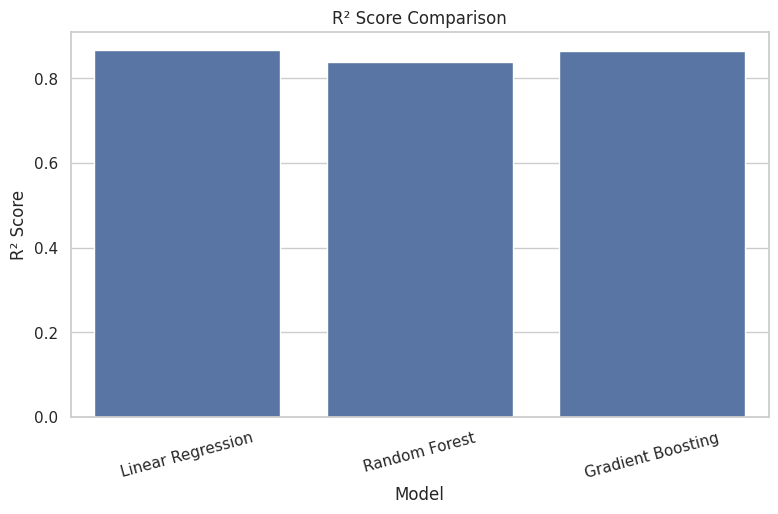

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("R² Score Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=15)

plt.show()

In [ ]:
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(),
    "Model"
]

print("Best model based on R²:", best_model_name)

Best model based on R²: Linear Regression


In [ ]:
model_dictionary = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest,
    "Gradient Boosting": gradient_boosting
}

prediction_dictionary = {
    "Linear Regression": linear_prediction,
    "Random Forest": rf_prediction,
    "Gradient Boosting": gb_prediction
}

best_model = model_dictionary[
    best_model_name
]

best_prediction = prediction_dictionary[
    best_model_name
]

In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": best_prediction
})

comparison.head(20)

,Actual,Predicted
0,37.0,29.479119
1,17.0,28.243031
2,70.0,66.147960
3,79.0,84.972329
4,54.0,49.998981
5,43.0,45.676797
6,52.0,48.305452
7,65.0,79.574918
8,37.0,35.450196
9,36.0,44.395172


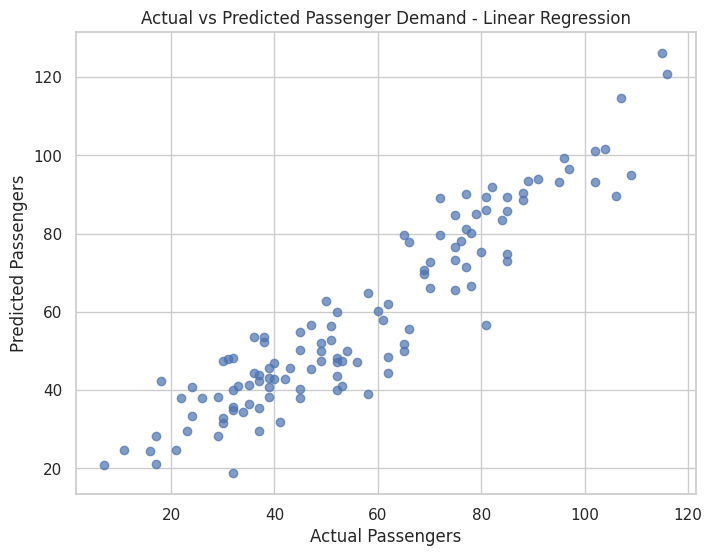

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_prediction,
    alpha=0.7
)

plt.xlabel("Actual Passengers")
plt.ylabel("Predicted Passengers")

plt.title(
    f"Actual vs Predicted Passenger Demand - {best_model_name}"
)

plt.grid(True)

plt.show()

In [ ]:
comparison["Error"] = (
    comparison["Actual"]
    - comparison["Predicted"]
)

comparison["Absolute_Error"] = (
    comparison["Error"].abs()
)

comparison.head(20)

,Actual,Predicted,Error,Absolute_Error
0,37.0,29.479119,7.520881,7.520881
1,17.0,28.243031,-11.243031,11.243031
2,70.0,66.147960,3.852040,3.852040
3,79.0,84.972329,-5.972329,5.972329
4,54.0,49.998981,4.001019,4.001019
5,43.0,45.676797,-2.676797,2.676797
6,52.0,48.305452,3.694548,3.694548
7,65.0,79.574918,-14.574918,14.574918
8,37.0,35.450196,1.549804,1.549804
9,36.0,44.395172,-8.395172,8.395172


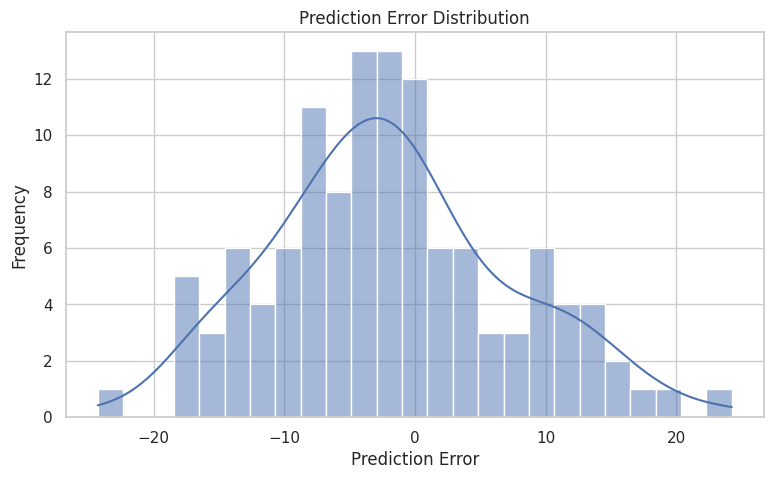

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    comparison["Error"],
    bins=25,
    kde=True
)

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

In [ ]:
new_trip = pd.DataFrame({
    "route_number": ["21G"],
    "hour": [8],
    "day_of_week": [0],
    "weather": ["Clear"],
    "holiday": [0],
    "bus_type": ["Ordinary"],
    "peak_hour": [1],
    "weekend": [0],
    "month": [9],
    "day": [21],
    "week_of_year": [39]
})

new_trip

,route_number,hour,day_of_week,weather,holiday,bus_type,peak_hour,weekend,month,day,week_of_year
0,21G,8,0,Clear,0,Ordinary,1,0,9,21,39


In [ ]:
prediction = best_model.predict(
    new_trip
)

predicted_passengers = round(
    prediction[0]
)

print(
    "Predicted Passenger Count:",
    predicted_passengers
)

Predicted Passenger Count: 111


In [ ]:
def get_demand_level(passengers):

    if passengers <= 40:
        return "Low"

    elif passengers <= 80:
        return "Medium"

    else:
        return "High"


demand_level = get_demand_level(
    predicted_passengers
)

print("Predicted Demand Level:", demand_level)

Predicted Demand Level: High


In [ ]:
test_trips = pd.DataFrame({
    "route_number": [
        "21G",
        "570",
        "101",
        "M1",
        "27B"
    ],

    "hour": [
        8,
        18,
        14,
        10,
        19
    ],

    "day_of_week": [
        0,
        2,
        4,
        5,
        1
    ],

    "weather": [
        "Clear",
        "Rain",
        "Cloudy",
        "Clear",
        "Clear"
    ],

    "holiday": [
        0,
        0,
        0,
        0,
        0
    ],

    "bus_type": [
        "Ordinary",
        "Ordinary",
        "Express",
        "Deluxe",
        "Ordinary"
    ],

    "peak_hour": [
        1,
        1,
        0,
        0,
        1
    ],

    "weekend": [
        0,
        0,
        0,
        1,
        0
    ],

    "month": [
        9,
        9,
        9,
        9,
        9
    ],

    "day": [
        21,
        23,
        25,
        27,
        22
    ],

    "week_of_year": [
        39,
        39,
        39,
        39,
        39
    ]
})

test_predictions = best_model.predict(
    test_trips
)

test_trips["Predicted_Passengers"] = (
    np.round(test_predictions).astype(int)
)

test_trips["Demand_Level"] = (
    test_trips["Predicted_Passengers"]
    .apply(get_demand_level)
)

test_trips

,route_number,hour,day_of_week,weather,holiday,bus_type,peak_hour,weekend,month,day,week_of_year,Predicted_Passengers,Demand_Level
0,21G,8,0,Clear,0,Ordinary,1,0,9,21,39,111,High
1,570,18,2,Rain,0,Ordinary,1,0,9,23,39,123,High
2,101,14,4,Cloudy,0,Express,0,0,9,25,39,52,Medium
3,M1,10,5,Clear,0,Deluxe,0,1,9,27,39,23,Low
4,27B,19,1,Clear,0,Ordinary,1,0,9,22,39,104,High


In [ ]:
model_file = "bus_passenger_demand_model.pkl"

joblib.dump(
    best_model,
    model_file
)

print(
    "Model saved as:",
    model_file
)

Model saved as: bus_passenger_demand_model.pkl


In [ ]:
files.download(
    "bus_passenger_demand_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
cleaned_file = "bus_passenger_demand_cleaned.csv"

df.to_csv(
    cleaned_file,
    index=False
)

print(
    "Cleaned dataset saved as:",
    cleaned_file
)

Cleaned dataset saved as: bus_passenger_demand_cleaned.csv


In [ ]:
files.download(
    "bus_passenger_demand_cleaned.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

files.download(
    "model_comparison_results.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>